<a href="https://colab.research.google.com/github/Cyber-GenAI/machine-learning/blob/main/GATTransformerLinkPredictor_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install torch_geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 51.9 MB/s  0:00:00


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import json
import copy
from numpy.random import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score
from torch_geometric.data import Data
import matplotlib.pyplot as plt
import scipy
from sklearn.metrics import roc_curve, auc
import random as rnd
import numpy as np
from torch_geometric.nn import (
    GATConv,
    TransformerConv
)
from numpy.random import random
from scipy.ndimage import gaussian_filter1d
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    average_precision_score
)
from torch_geometric import transforms as T

seed = 42

random(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [7]:
import torch_geometric
print(f"PyTorch Geometric version: {torch_geometric.__version__}")

PyTorch Geometric version: 2.8.1


In [10]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl
import os
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Times New Roman"],
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.linewidth": 0.8,
    "grid.linestyle": "--",
    "grid.alpha": 0.2
})

In [11]:
import os

class Config:
    #DATA_PATH = "/opt/cyber_genai/src/cyber_graph/datasets/apt_group_techniques.json"
    DATA_PATH="/content/drive/MyDrive/cyber_genai/.data/cyber_data/.json/apt_group_techniques.json"
    CHECKPOINT_DIR = "/content/checkpoints"
    HIDDEN_CHANNELS = 128
    NUM_HEADS = 4
    DROPOUT = 0.1
    LEARNING_RATE = 1e-3
    WEIGHT_DECAY = 1e-4
    EPOCHS = 300
    PATIENCE = 40
    FACTORE=0.5
    TOP_K=5
    NUM_VALUE=0.2
    NUM_TEST=0.1
    DEVICE = torch.device("cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

os.makedirs(Config.CHECKPOINT_DIR, exist_ok=True)
BEST_MODEL_PATH = os.path.join(
        Config.CHECKPOINT_DIR,
        "best_model.pt"
)
print(Config.DEVICE)


cuda


In [12]:
def build_graph(data_path):

    with open(data_path, "r", encoding="utf-8") as f:
        data_dict = json.load(f)
    all_techniques = []
    edges = []
    for group_data in data_dict.values():
        if isinstance(group_data, dict):
            if "sequence" not in group_data:
                continue
            sequence = group_data["sequence"]
            if not isinstance(sequence, list):
                continue
            t_ids = [
                t.get("external_id")
                for t in sequence
                if t.get("external_id")
            ]
            all_techniques.extend(t_ids)
            for i in range(len(t_ids) - 1):
                src = t_ids[i]
                dst = t_ids[i + 1]
                edges.append((src, dst))
                edges.append((dst, src))
                unique_techniques = sorted(
        list(set(all_techniques))
    )

    if len(unique_techniques) == 0:
        raise ValueError("No techniques found.")

    le = LabelEncoder()
    #print(unique_techniques.shape)
    le.fit(unique_techniques)

    edge_index = []

    for src, dst in edges:

        edge_index.append([
            le.transform([src])[0],
            le.transform([dst])[0]
        ])

    edge_index = torch.tensor(
        edge_index,
        dtype=torch.long
    ).t().contiguous()

    data = Data(
        edge_index=edge_index,
        num_nodes=len(unique_techniques)
    )

    print(
        f"Graph created: "
        f"{data.num_nodes} nodes, "
        f"{data.num_edges} edges"
    )

    return data, le, unique_techniques

In [13]:
def build_technique_names(data_path):

    names = {}
    with open(data_path, "r", encoding="utf-8") as f:
        data_dict = json.load(f)

    for group in data_dict.values():
        if not isinstance(group, dict):
            continue
        if "sequence" not in group:
            continue
        for item in group["sequence"]:
            tid = item.get("external_id")
            name = item.get("name")
            if tid and name:
                names[tid] = name
    return names

technique_names = build_technique_names(Config.DATA_PATH)

In [14]:
class GATTransformerLinkPredictor(nn.Module):

    def __init__( self,num_nodes,hidden_channels,num_heads=Config.NUM_HEADS,dropout=Config.DROPOUT):
        super().__init__()
        self.embedding = nn.Embedding( num_nodes,hidden_channels)

        self.gat = GATConv(
            hidden_channels,
            hidden_channels,
            heads=num_heads,
            dropout=dropout,
            concat=True
        )
        self.norm1 = nn.LayerNorm(
            hidden_channels * num_heads
        )
        self.transformer = TransformerConv(
            hidden_channels * num_heads,
            hidden_channels,
            heads=num_heads,
            concat=False,
            beta=True,
            dropout=dropout
        )
        self.norm2 = nn.LayerNorm(
            hidden_channels
        )
        self.dropout = dropout
        self.decoder = nn.Sequential(nn.Linear(hidden_channels * 2,hidden_channels),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear( hidden_channels, hidden_channels // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_channels // 2,1)
        )
    def forward( self,node_idx,edge_index,edge_label_index):
            x = self.embedding(node_idx)
            h1 = self.gat( x,edge_index)
            h1 = F.elu(h1)
            h1 = self.norm1(h1)
            h1 = F.dropout(h1, p=self.dropout,training=self.training)
            h2 = self.transformer(h1,edge_index)
            h2 = self.norm2(h2)
            residual = h1[:, :h2.shape[1]]
            h = h2 + residual
            src, dst = edge_label_index
            z = torch.cat(
                [
                    h[src],
                    h[dst]
                ],
                dim=-1
            )
            return self.decoder(z).view(-1)

In [15]:
def train(model,data,optimizer,criterion,device):

    model.train()
    optimizer.zero_grad()
    node_idx = torch.arange(data.num_nodes,device=device)

    out = model(node_idx,data.edge_index.to(device),data.edge_label_index.to(device))
    loss = criterion(out,data.edge_label.to(device))
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
    optimizer.step()
    return loss.item()

In [16]:
@torch.no_grad()
def evaluate(model, data, device):

    model.eval()
    node_idx = torch.arange(data.num_nodes,device=device)
    out = model(node_idx,data.edge_index.to(device),data.edge_label_index.to(device)
    )
    preds = out.sigmoid().cpu().numpy()
    labels = data.edge_label.cpu().numpy()
    return roc_auc_score(
        labels,
        preds
    )


In [17]:
@torch.no_grad()
def predict_next_techniques(model,le,unique_techniques,technique_names,data,technique_id,
    top_k=Config.TOP_K,
    device=Config.DEVICE
):
    model.eval()
    if technique_id not in le.classes_:
        return []
    src_idx = le.transform([technique_id])[0]
    num_nodes = data.num_nodes
    src_nodes = torch.full((num_nodes,),src_idx,device=device)
    dst_nodes = torch.arange(num_nodes,device=device)
    edge_label_index = torch.stack(
        [
            src_nodes,
            dst_nodes
        ]
    )
    node_idx = torch.arange(
        num_nodes,
        device=device
    )
    with torch.no_grad():
        preds = model(
            node_idx,
            data.edge_index.to(device),
            edge_label_index
        )
    preds = preds.sigmoid()

    preds[src_idx] = -1
    existing_edges = set(
        zip(
            data.edge_index[0].tolist(),
            data.edge_index[1].tolist()
        )
    )

    values, indices = torch.topk(
        preds,
        k=num_nodes
    )

    results = []

    for value, idx in zip(values, indices):

        dst_idx = idx.item()

        if (src_idx, dst_idx) in existing_edges:
            continue

        technique_id = le.inverse_transform(
        [dst_idx]
        )[0]

        results.append({

        "technique_id": technique_id,
        "technique_name":technique_names.get(technique_id,"Unknown"),
        "probability":
        float(value.item())
        })

        if len(results) >= top_k:
            break

    return results

In [18]:
@torch.no_grad()
def get_test_predictions(model, data, device):

    model.eval()
    node_idx = torch.arange(
        data.num_nodes,
        device=device
    )
    out = model(
        node_idx,
        data.edge_index.to(device),
        data.edge_label_index.to(device)
    )
    scores = out.sigmoid().cpu().numpy()
    labels = data.edge_label.cpu().numpy()
    return labels, scores

@torch.no_grad()
def get_roc_data(model, data, device):

    model.eval()
    node_idx = torch.arange(data.num_nodes,device=device)
    out = model(node_idx,data.edge_index.to(device),data.edge_label_index.to(device))
    scores = out.sigmoid().cpu().numpy()
    labels = data.edge_label.cpu().numpy()
    fpr, tpr, _ = roc_curve(labels,scores)
    roc_auc = auc(fpr,tpr)
    return fpr, tpr, roc_auc

In [19]:
from matplotlib import cm
def plot_confusion_matrix(y_true, y_scores,threshold=0.5):

    y_pred = ( y_scores >= threshold).astype(int)

    cm = confusion_matrix(y_true,y_pred)
    fig, ax = plt.subplots(figsize=(6,6))
    disp = ConfusionMatrixDisplay( confusion_matrix=cm,display_labels=["Negative","Positive"])
    disp.plot(ax=ax,cmap="viridis",colorbar=True)
    plt.title(f"Confusion Matrix\nThreshold={threshold}")
    plt.tight_layout()
    plt.show()

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, average_precision_score

# ============================================
# تنظیمات سراسری استاندارد IEEE
# ============================================
IEEE_FIG_WIDTH = 3.5          # اینچ (عرض تک‌ستون)
IEEE_FIG_HEIGHT = 2.8         # اینچ (نسبت طلایی)
FONT_SIZE = 9                 # پوینت (پیشنهاد IEEE)

plt.rcParams.update({
    # ---------- فونت ----------
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": FONT_SIZE,

    # ---------- اندازه‌های فونت ----------
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE - 1,
    "ytick.labelsize": FONT_SIZE - 1,
    "legend.fontsize": FONT_SIZE - 1,

    # ---------- ابعاد و رزولوشن ----------
    "figure.figsize": (IEEE_FIG_WIDTH, IEEE_FIG_HEIGHT),
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,

    # ---------- ضخامت خطوط ----------
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.5,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})

# ============================================
# تابع کمکی برای اعمال استایل IEEE روی محورها
# ============================================
def apply_ieee_style(ax):
    """حذف خطوط بالایی و راستی و تنظیم خطوط محور"""
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(0.8)
    ax.spines['bottom'].set_linewidth(0.8)
    ax.tick_params(direction='out', length=4, width=0.8)
    return ax

In [21]:
def smooth_curve(values, window=7):
    """میانگین‌گیری متحرک برای هموارسازی"""
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window)/window, mode='valid')

def plot_training_loss(losses):
    epochs = np.arange(1, len(losses) + 1)
    smooth_loss = smooth_curve(losses, window=7)

    fig, ax = plt.subplots(figsize=(IEEE_FIG_WIDTH, IEEE_FIG_HEIGHT))

    # داده‌های خام (با شفافیت بالا)
    ax.plot(epochs, losses, color="orangered", alpha=0.85, linestyle="--", linewidth=0.85, label="Raw Loss")

    # منحنی هموار (با ضخامت بیشتر)
    ax.plot(epochs[:len(smooth_loss)],smooth_loss, color="black", linewidth=0.8, label="Smoothed Loss")

    # نقطه کمترین مقدار
    min_idx = np.argmin(losses)
    ax.scatter(min_idx + 1, losses[min_idx], color="gold", marker="*", s=30, label="Min Loss")

    # برچسب‌ها
    ax.set_xlabel("Epoch", fontsize=FONT_SIZE)
    ax.set_ylabel("Loss", fontsize=FONT_SIZE)

    # استایل IEEE
    apply_ieee_style(ax)
    ax.grid(True, linestyle=':', alpha=0.3, linewidth=0.5)

    # افسانه (بدون کادر)
    ax.legend(frameon=False, fontsize=FONT_SIZE-1)

    plt.tight_layout()
    plt.show()

def plot_validation_auc(val_aucs):
    epochs = np.arange(1, len(val_aucs) + 1)
    smooth_auc = smooth_curve(val_aucs, window=7)

    fig, ax = plt.subplots(figsize=(IEEE_FIG_WIDTH, IEEE_FIG_HEIGHT))

    # داده‌های خام
    ax.plot(epochs, val_aucs, color="orangered", alpha=0.85,linestyle="--", linewidth=0.85, label="Raw AUC")

    # منحنی هموار
    ax.plot(epochs[:len(smooth_auc)], smooth_auc, color="black", linewidth=0.8, label="Smoothed AUC")

    # بهترین دوره
    best_epoch = np.argmax(val_aucs) + 1
    ax.scatter(best_epoch, val_aucs[best_epoch - 1], color="gold", marker="*", s=60, label="Best Epoch")

    ax.set_xlabel("Epoch", fontsize=FONT_SIZE)
    ax.set_ylabel("AUC", fontsize=FONT_SIZE)

    apply_ieee_style(ax)
    ax.grid(True, linestyle=':', alpha=0.3, linewidth=0.5)
    ax.legend(frameon=False, fontsize=FONT_SIZE-1)

    plt.tight_layout()
    plt.show()

def plot_training_history(losses, val_aucs):
    plot_training_loss(losses)
    plot_validation_auc(val_aucs)

def plot_roc_curve(fpr, tpr, roc_auc):
    fig, ax = plt.subplots(figsize=(IEEE_FIG_WIDTH, IEEE_FIG_WIDTH))  # مربعی

    ax.plot(fpr, tpr, linewidth=1.0, color="orangered",linestyle="--", label=f"AUC = {roc_auc:.4f}")
    ax.plot([0, 1], [0, 1], linestyle="--", color="black", linewidth=0.8, alpha=0.7)

    ax.set_xlabel("False Positive Rate", fontsize=FONT_SIZE)
    ax.set_ylabel("True Positive Rate", fontsize=FONT_SIZE)

    apply_ieee_style(ax)
    ax.grid(True, linestyle=':', alpha=0.2, linewidth=0.5)
    ax.legend(frameon=False, fontsize=FONT_SIZE-1, loc='lower right')

    plt.tight_layout()
    plt.show()

def plot_precision_recall_curve(y_true, y_scores):
    precision, recall, _ = precision_recall_curve(y_true, y_scores)
    ap_score = average_precision_score(y_true, y_scores)

    fig, ax = plt.subplots(figsize=(IEEE_FIG_WIDTH, IEEE_FIG_HEIGHT))

    # منحنی اصلی
    ax.plot(recall, precision, linewidth=1.0, color="orangered",linestyle="--", label=f"AP = {ap_score:.4f}")

    # خط مبنا (میانگین کلاس مثبت)
    baseline = np.mean(y_true)
    ax.hlines(y=baseline, xmin=0, xmax=1, linestyles="--", colors="black", linewidth=0.8, label="Baseline")

    ax.set_xlabel("Recall", fontsize=FONT_SIZE)
    ax.set_ylabel("Precision", fontsize=FONT_SIZE)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])

    apply_ieee_style(ax)
    ax.grid(True, linestyle=':', alpha=0.2, linewidth=0.5)
    ax.legend(frameon=False, fontsize=FONT_SIZE-1, loc='lower left')

    plt.tight_layout()
    plt.show()
    return ap_score

In [ ]:
# import matplotlib.pyplot as plt

# colors = ["orange", "darkorange", "orangered", "chocolate"]
# for i, color in enumerate(colors):
#     plt.plot([0, 1], [i, i], color=color, linewidth=3, label=color)
# plt.legend()
# plt.show()

In [22]:
import matplotlib.pyplot as plt
import numpy as np

def _plot_predictions_(predictions):
    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times", "DejaVu Serif", "STIXGeneral"],
        "font.size": 9
    })
    predictions = sorted(
        predictions,
        key=lambda x: float(x["probability"]),
        reverse=False
    )

    tech_ids = [p["technique_id"] for p in predictions]
    tech_names = [p.get("technique_name", "") for p in predictions]
    probs = np.array([float(p["probability"]) for p in predictions])
    N = len(probs)

    fig = plt.figure(figsize=(8.5, 4.5))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.4, 1], wspace=0.0)

    ax_table = fig.add_subplot(gs[0])
    ax_bar = fig.add_subplot(gs[1])

    y_pos = np.arange(N)
    y_min, y_max = -0.5, N + 0.5

    colors = plt.cm.Reds(np.linspace(0.4, 0.9, N))
    bars = ax_bar.barh(y_pos, probs, color=colors, height=0.5, edgecolor='none')  # ارتفاع کمتر

    # قرار دادن عدد احتمال در انتهای سمت راست میله (داخل آن)
    for bar, prob in zip(bars, probs):
        # اگر میله خیلی کوتاه است، عدد را بیرون قرار ندهید (اینجا همیشه داخل می‌گذاریم)
        x_text = prob - 0.015  # فاصله از لبه راست
        # برای خوانایی بهتر، اگر میله تیره است از سفید و اگر روشن است از مشکی استفاده کنید
        # (در اینجا ساده گرفته شده)
        ax_bar.text(x_text, bar.get_y() + bar.get_height()/2, f'{prob:.3f}',
                    va='center', ha='right', fontsize=8, color='white', weight='bold')

    ax_bar.set_ylim(y_min, y_max)
    ax_bar.set_xlim(0, max(probs) + 0.05)  # نمایش کامل میله‌ها با کمی فضا
    ax_bar.set_xlabel('Prediction Probability', fontsize=10, weight='bold')
    ax_bar.set_yticks([])
    ax_bar.spines['top'].set_visible(False)
    ax_bar.spines['right'].set_visible(False)
    ax_bar.spines['left'].set_visible(False)
    ax_bar.grid(axis='x', linestyle=':', alpha=0.6)

    # بخش رسم جدول تکنیک‌ها (سمت چپ)
    ax_table.set_ylim(y_min, y_max)
    ax_table.set_xlim(0, 1)
    ax_table.axis('off')

    for i in range(N + 1):
        y = i - 0.5
        ax_table.plot([0, 1], [y, y], color='black', lw=0.5 if i != 0 and i != N else 1.2)

    ax_table.set_ylim(-0.5, N + 0.5)
    ax_table.plot([0, 1], [N + 0.5, N + 0.5], color='black', lw=1.5)
    ax_table.plot([0, 1], [N - 0.5, N - 0.5], color='black', lw=1.0)
    ax_table.plot([0, 1], [-0.5, -0.5], color='black', lw=1.5)

    # هدرهای تراز‌شده با ستون‌های جدول
    ax_table.text(0.01, N, 'Technique ID',
                  va='center', ha='left', weight='bold', fontsize=9)
    ax_table.text(0.32, N, 'Technique Name',
                  va='center', ha='left', weight='bold', fontsize=9)

    for i in range(N):
        ax_table.text(0.01, y_pos[i], tech_ids[i], va='center', ha='left', fontsize=9)
        ax_table.text(0.32, y_pos[i], tech_names[i], va='center', ha='left', fontsize=9)

    plt.tight_layout()
    plt.show()

Graph created: 458 nodes, 7784 edges

Starting training...
loss:0.7052004933357239
val_auc:0.7380469333403824
Best model saved (AUC=0.7380)
loss:0.6710042953491211
val_auc:0.7967590420364655
Best model saved (AUC=0.7968)
loss:0.6502389907836914
val_auc:0.8183315600610623
Best model saved (AUC=0.8183)
loss:0.6271998882293701
val_auc:0.8217002266704556
Best model saved (AUC=0.8217)
loss:0.6003267765045166
val_auc:0.8169983016237007
loss:0.5714684128761292
val_auc:0.8234878172890743
Best model saved (AUC=0.8235)
loss:0.538266658782959
val_auc:0.835164980405892
Best model saved (AUC=0.8352)
loss:0.5072458982467651
val_auc:0.8440566742223485
Best model saved (AUC=0.8441)
loss:0.4723978340625763
val_auc:0.851410247090622
Best model saved (AUC=0.8514)
loss:0.44507378339767456
val_auc:0.8601879448325085
Best model saved (AUC=0.8602)
Epoch 010 | Loss 0.4451 | Val AUC 0.8602
loss:0.4175821542739868
val_auc:0.867700120934966
Best model saved (AUC=0.8677)
loss:0.395463228225708
val_auc:0.873725391

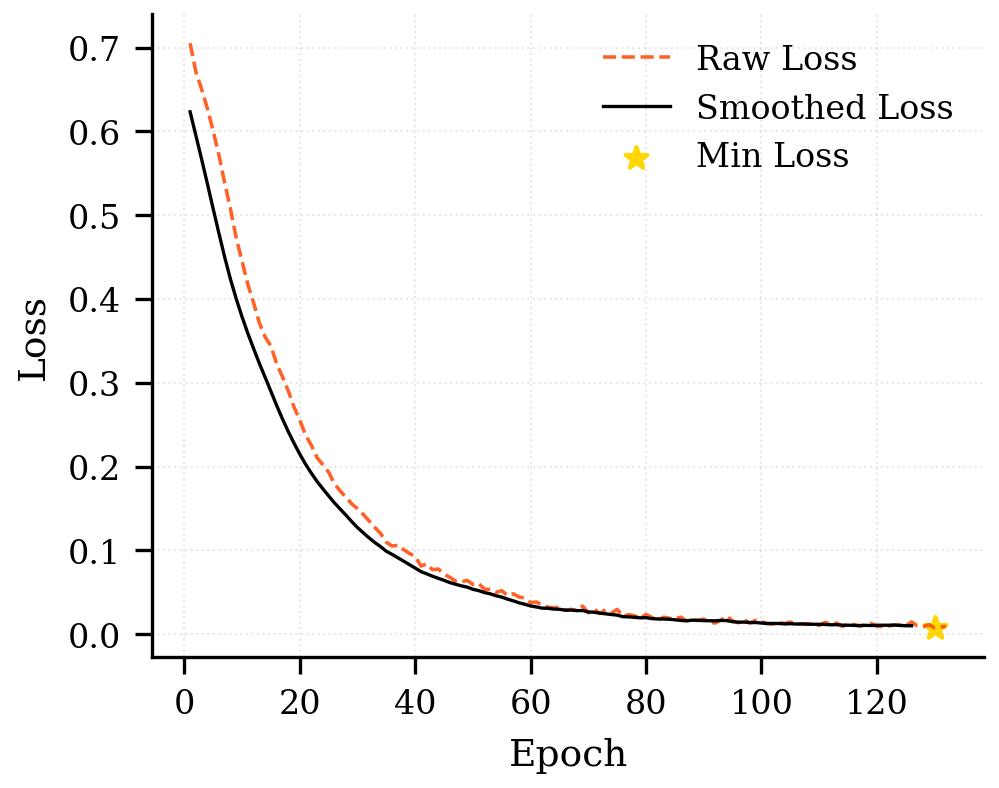

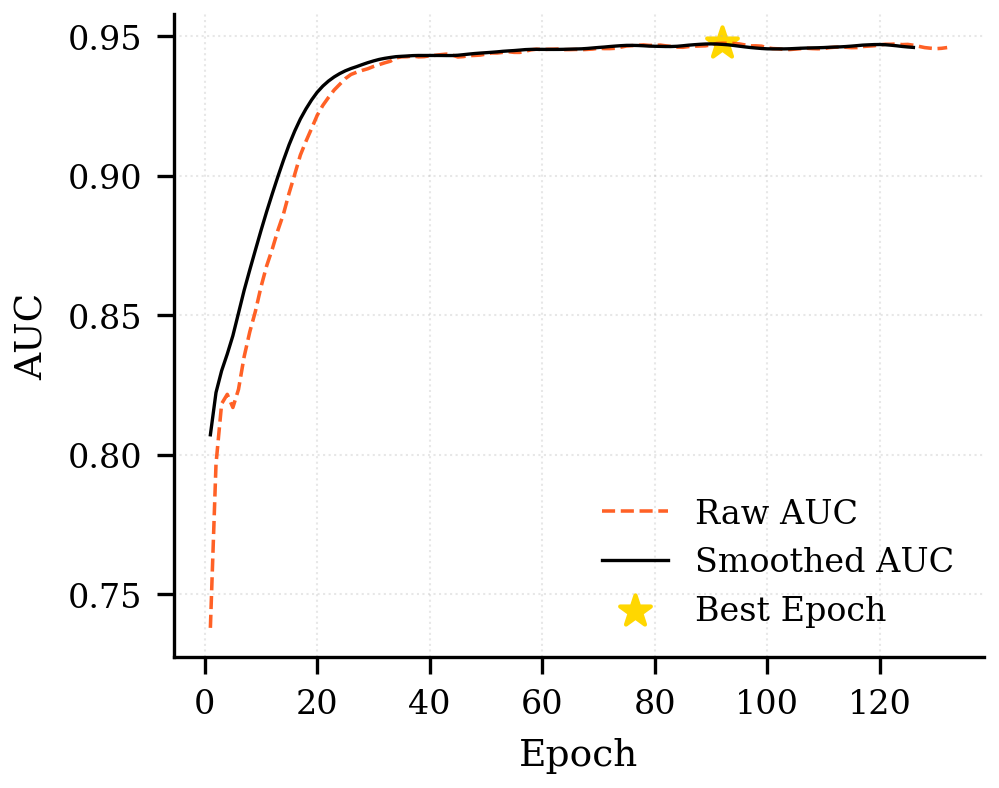


Final Test AUC: 0.9565


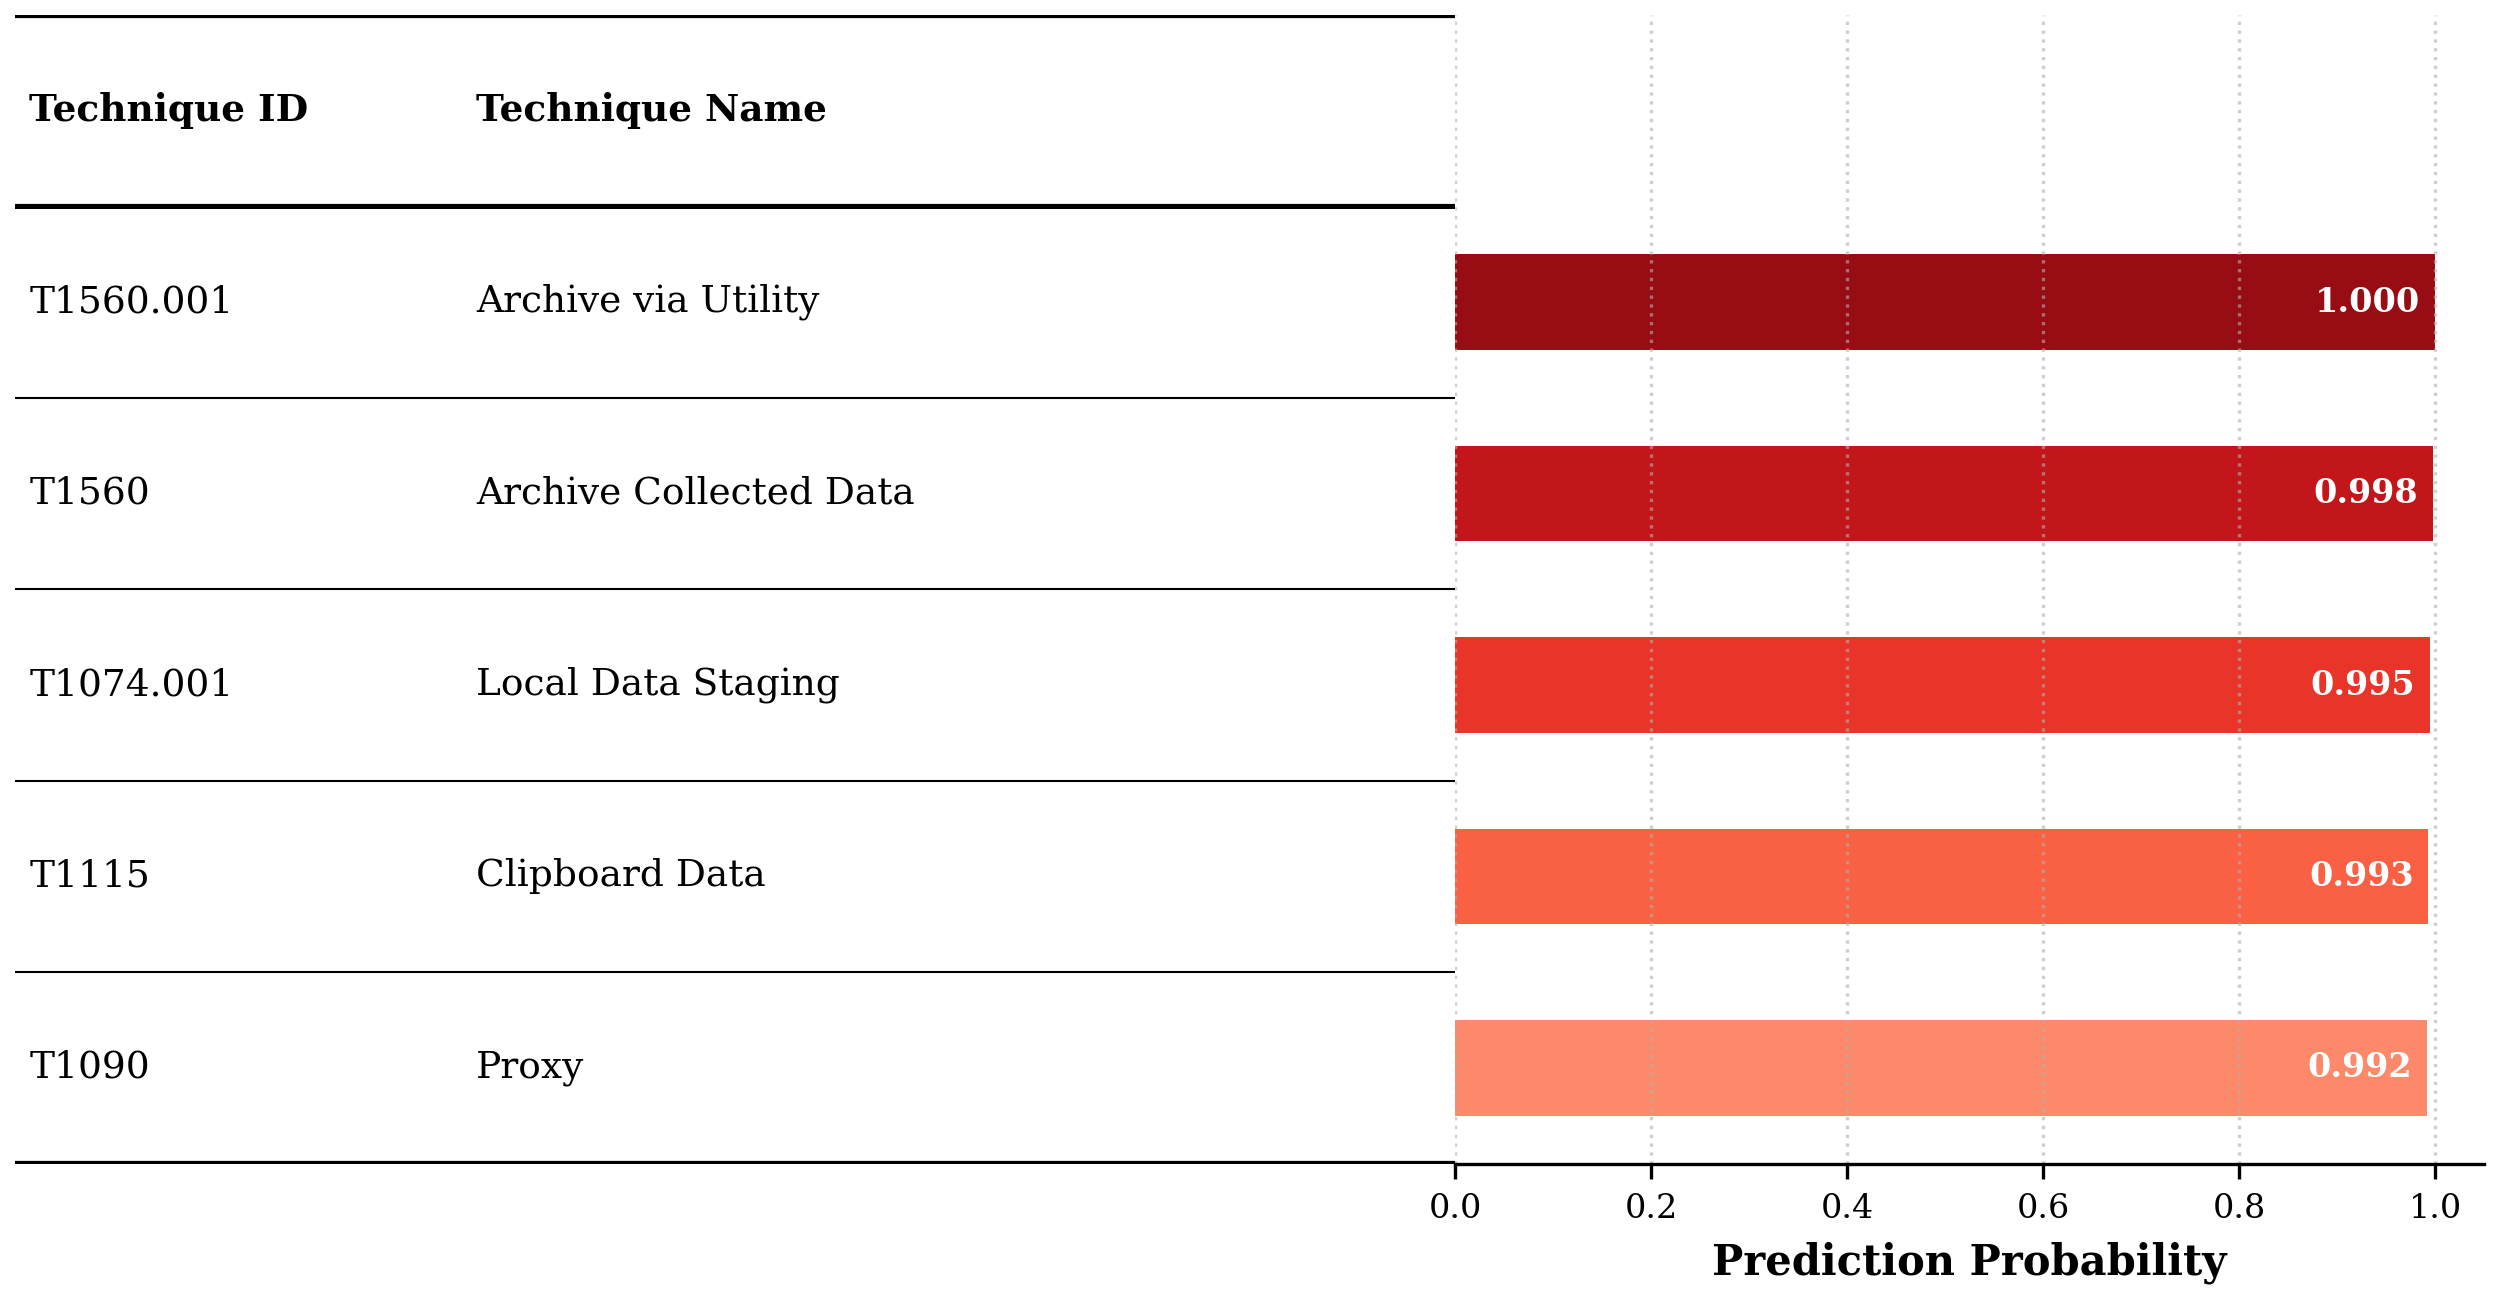


Top predictions for T1001:
[
  {
    "technique_id": "T1560.001",
    "technique_name": "Archive via Utility",
    "probability": 0.9998347759246826
  },
  {
    "technique_id": "T1560",
    "technique_name": "Archive Collected Data",
    "probability": 0.997946560382843
  },
  {
    "technique_id": "T1074.001",
    "technique_name": "Local Data Staging",
    "probability": 0.9946531057357788
  },
  {
    "technique_id": "T1115",
    "technique_name": "Clipboard Data",
    "probability": 0.9931748509407043
  },
  {
    "technique_id": "T1090",
    "technique_name": "Proxy",
    "probability": 0.991786777973175
  }
]
y_true = [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 

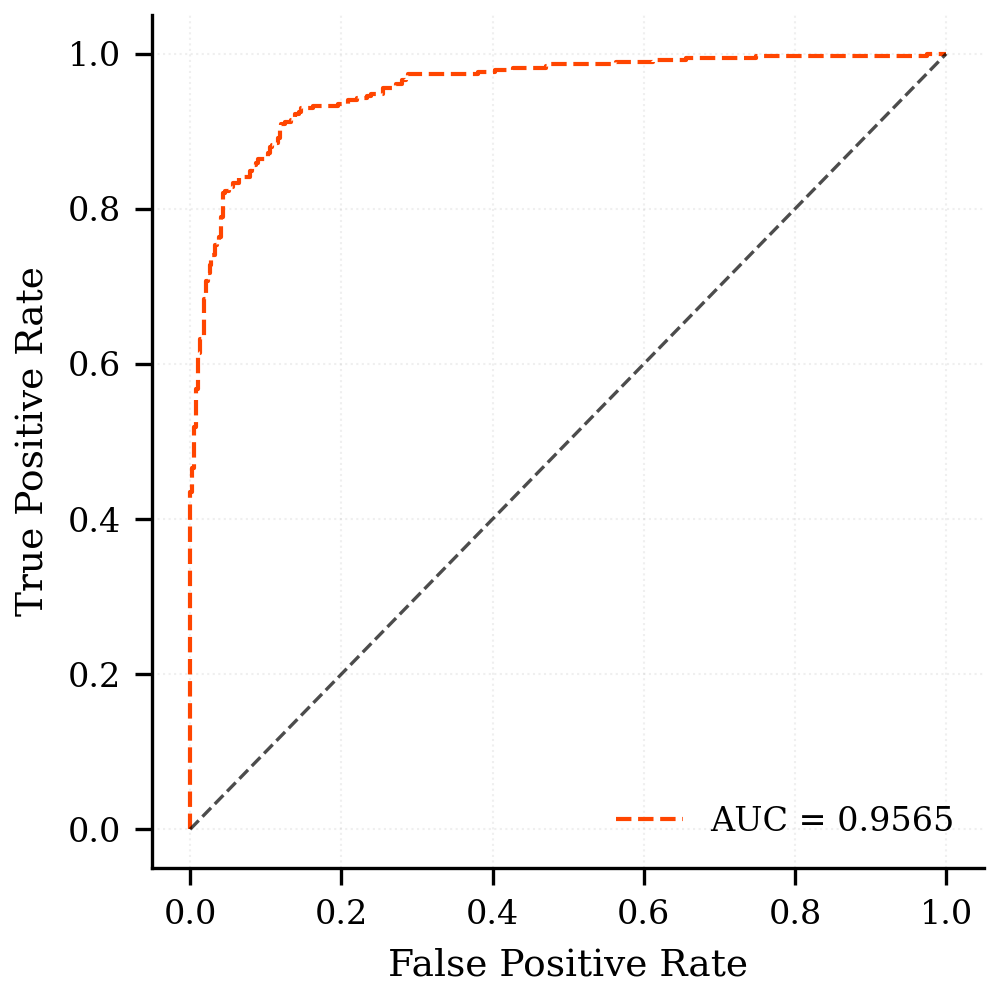

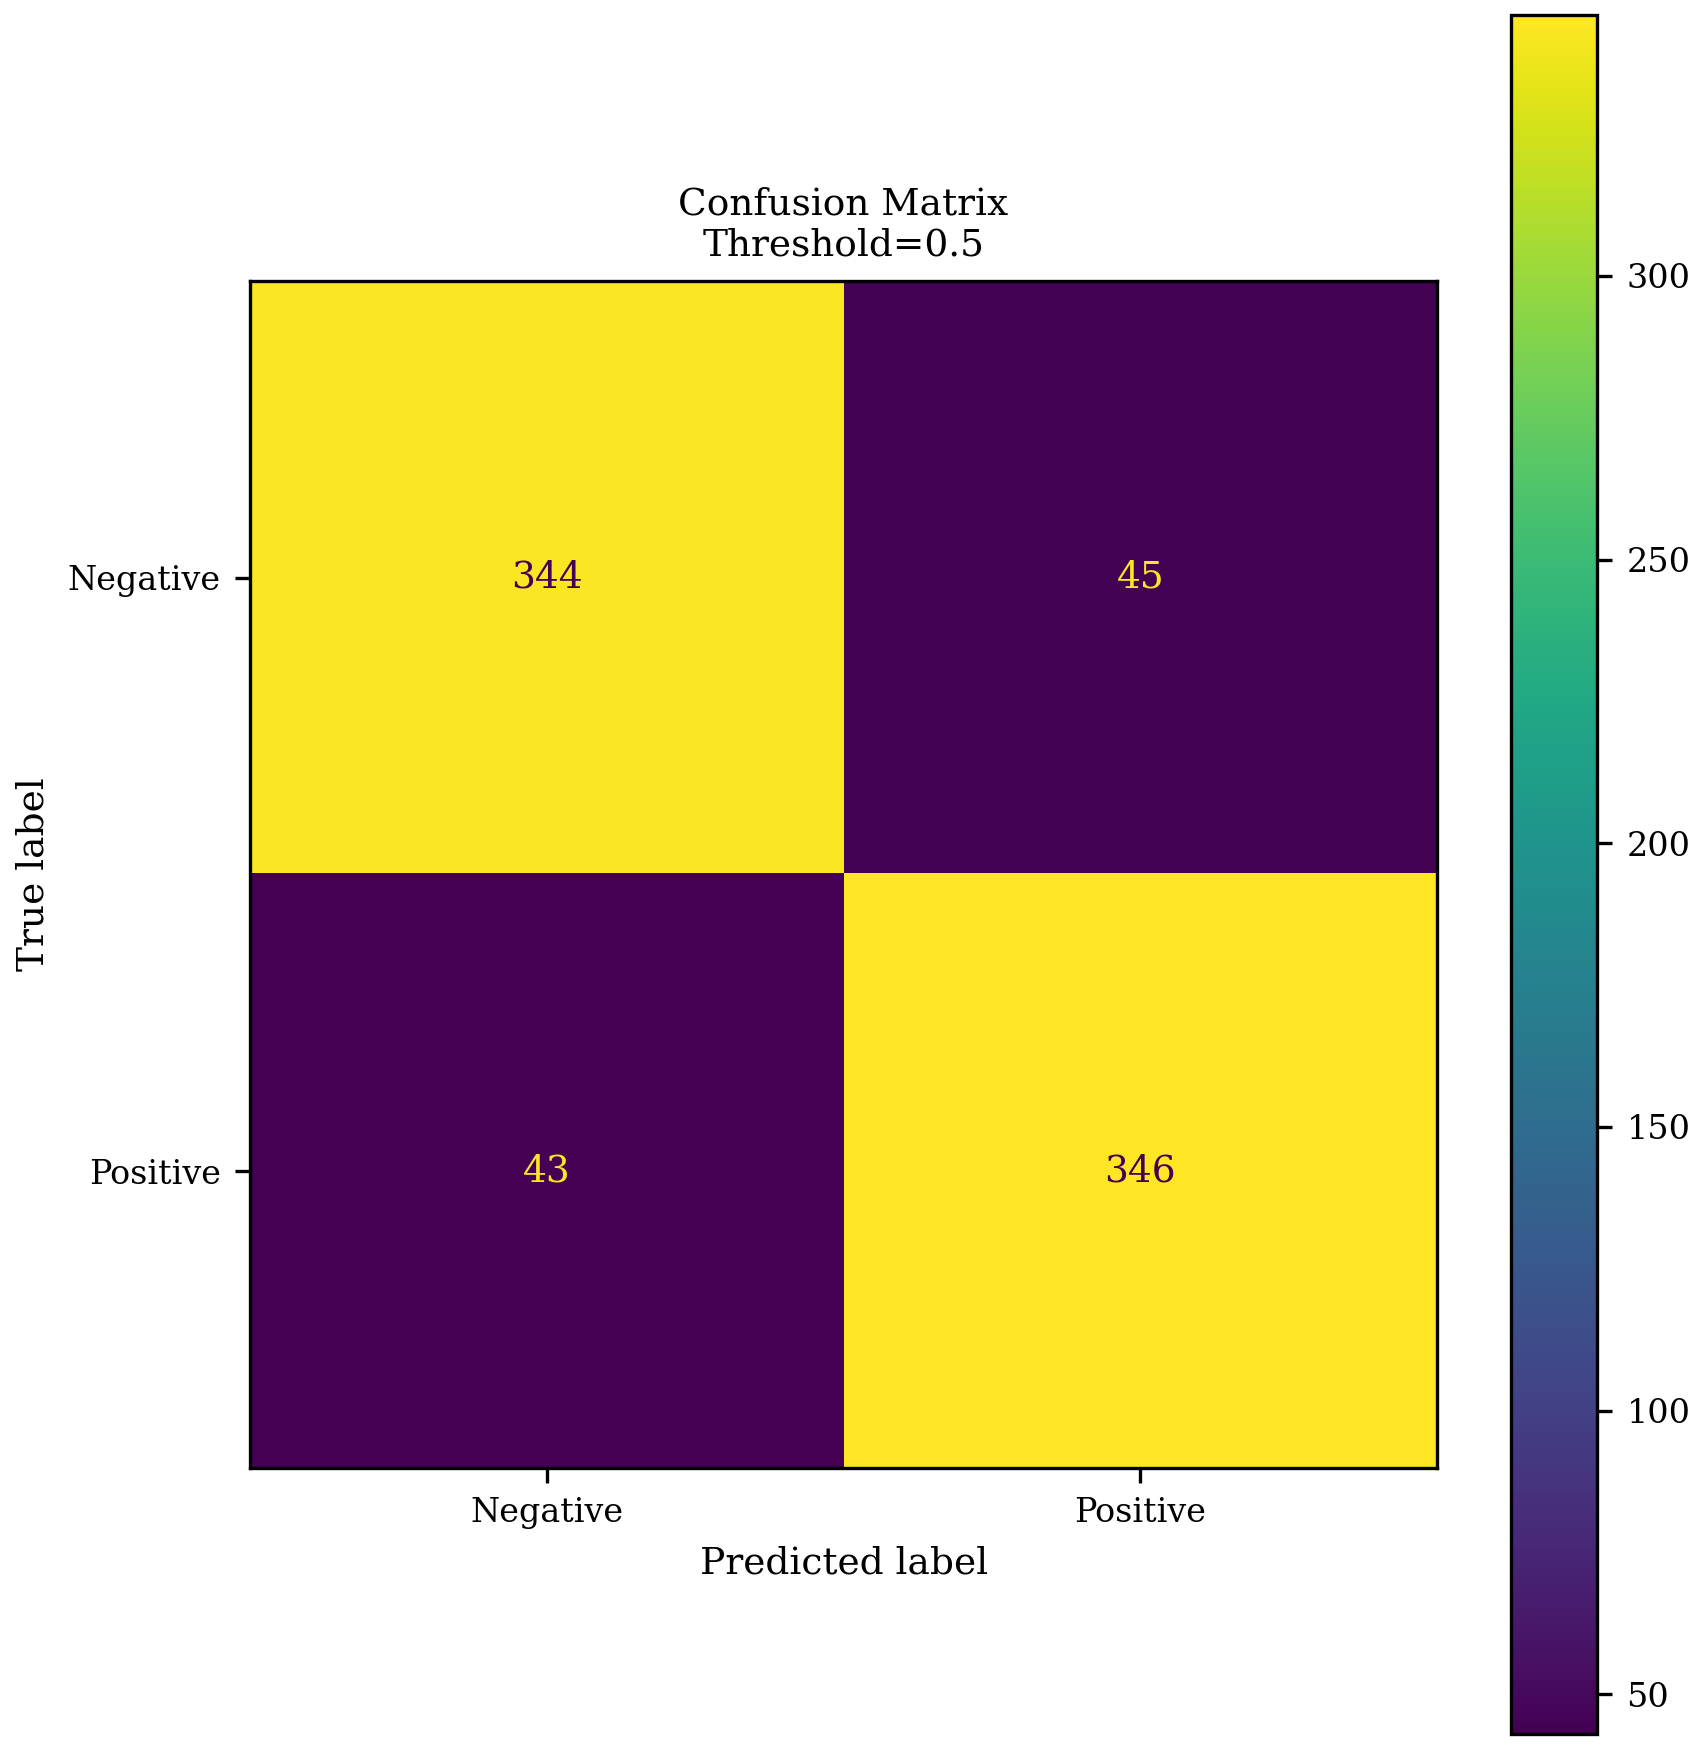

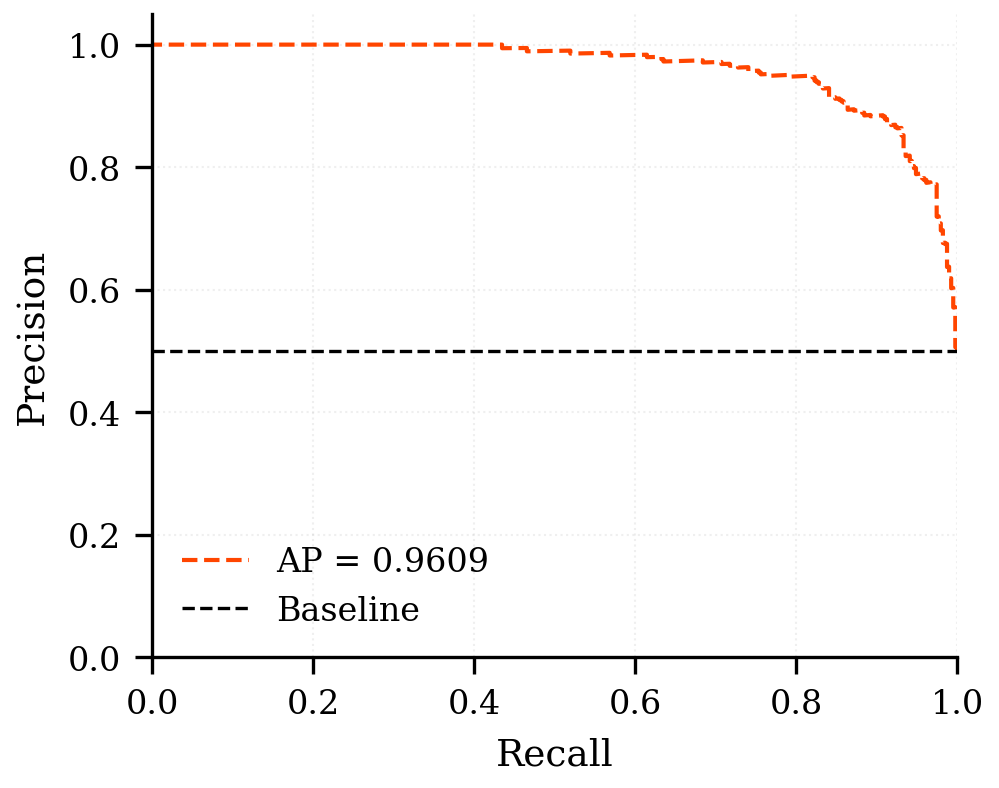

Average Precision: 0.9609


In [ ]:
from numpy.random import random


if __name__ == "__main__":

    data, le, unique_techniques = build_graph(
        Config.DATA_PATH
    )

    torch.manual_seed(42)

    transform = T.RandomLinkSplit(
        num_val=Config.NUM_VALUE,
        num_test=Config.NUM_TEST,
        is_undirected=True,
        add_negative_train_samples=True
    )

    train_data, val_data, test_data = transform(
        data
    )

    model = GATTransformerLinkPredictor(
        num_nodes=data.num_nodes,
        hidden_channels=Config.HIDDEN_CHANNELS,
        num_heads=Config.NUM_HEADS,
        dropout=Config.DROPOUT
    ).to(Config.DEVICE)

    optimizer = optim.AdamW(
        model.parameters(),
        lr=Config.LEARNING_RATE,
        weight_decay=Config.WEIGHT_DECAY
    )

    criterion = nn.BCEWithLogitsLoss()

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        patience=Config.PATIENCE,
        factor=Config.FACTORE
    )

    best_auc = 0
    patience_counter = 0
    best_model = None
    train_losses = []
    val_aucs = []

    print("\nStarting training...")
    for epoch in range( 1,
        Config.EPOCHS + 1
    ):

        loss = train(
            model,
            train_data,
            optimizer,
            criterion,
            Config.DEVICE
        )

        val_auc = evaluate(
            model,
            val_data,
            Config.DEVICE
        )

        train_losses.append(loss)
        print(f"loss:{loss}")
        val_aucs.append(val_auc)
        print(f"val_auc:{val_auc}")
        scheduler.step(val_auc)

        if val_auc > best_auc:
            best_auc = val_auc
            patience_counter = 0
            best_model = copy.deepcopy(
                model.state_dict()
            )
            torch.save(
                best_model,
                BEST_MODEL_PATH
            )

            print(
                f"Best model saved "
                f"(AUC={best_auc:.4f})"
            )
        else:
            patience_counter += 1
        if epoch % 10 == 0:
            print(
                f"Epoch {epoch:03d} | "
                f"Loss {loss:.4f} | "
                f"Val AUC {val_auc:.4f}"
            )
        if patience_counter >= Config.PATIENCE:
            print("Early stopping.")
            break

    state_dict = torch.load(
        BEST_MODEL_PATH,
        map_location=Config.DEVICE,
        weights_only=True
    )
    model.load_state_dict(state_dict)

    plot_training_history(train_losses,val_aucs)
    model.eval()
    test_auc = evaluate(model,test_data,Config.DEVICE)
    print(f"\nFinal Test AUC: "f"{test_auc:.4f}")

    test_id = unique_techniques[0]
    #test_id = np.random.choice(unique_techniques)



    #model.eval()
    predictions = predict_next_techniques(
        model,
        le,
        unique_techniques,
        technique_names,
        data,
        test_id,
        top_k=Config.TOP_K,
        device=Config.DEVICE
    )
    #print(model.training)
    _plot_predictions_(predictions)
    #plt.savefig("/opt/cyber_genai/src/cyber_graph/plots/output.png", dpi=300)

    print(f"\nTop predictions for "f"{test_id}:")
    print(json.dumps(predictions,indent=2))


    # 8. Prediction Scores
    y_true, y_scores = get_test_predictions(model,test_data,Config.DEVICE)
    fpr, tpr, roc_auc = get_roc_data(model,test_data,Config.DEVICE)

    print("y_true =", y_true, "y_scores =", y_scores)
    print("fpr =", fpr, "tpr =", tpr, "roc_auc =", roc_auc)

    plot_roc_curve(fpr,tpr,roc_auc)
    plot_confusion_matrix(y_true,y_scores)
    ap_score = plot_precision_recall_curve(y_true,y_scores)

    print(f"Average Precision: "f"{ap_score:.4f}")



In [24]:
# =============================================================================
# FULL multi-seed evaluation: GNN baselines + heuristic baselines + GraphATT-Trans
# Same HP as Bayesian best (Table III). is_undirected=True.
# Reports mean±std, 95% CI, paired t-tests.
# =============================================================================
import copy
import json
import math
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
)
from torch_geometric import transforms as T
from torch_geometric.nn import GCNConv, SAGEConv, GATConv, TransformerConv

# -------------------- experiment config --------------------
HP = dict(
    hidden_channels=128,
    num_heads=4,
    dropout=0.1,
    lr=1e-3,
    weight_decay=1e-4,
    epochs=300,
    patience=40,
    num_val=0.2,
    num_test=0.1,
)
SEEDS = [42, 7, 123, 2024, 99]
DEVICE = Config.DEVICE
DATA_PATH = Config.DATA_PATH

METRIC_KEYS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "AP"]

def set_seed(seed: int):
    import random as pyrand
    pyrand.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def metrics_from_scores(y_true, y_score, thr=0.5):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)
    y_pred = (y_score >= thr).astype(int)
    return {
        "Accuracy": 100 * accuracy_score(y_true, y_pred),
        "Precision": 100 * precision_score(y_true, y_pred, zero_division=0),
        "Recall": 100 * recall_score(y_true, y_pred, zero_division=0),
        "F1": 100 * f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": 100 * roc_auc_score(y_true, y_score),
        "AP": 100 * average_precision_score(y_true, y_score),
    }

# -------------------- GNN baselines (shared decoder style) --------------------
class BaseLinkPredictor(nn.Module):
    """Embedding + one conv family + MLP decoder (same HP width)."""
    def __init__(self, num_nodes, hidden=128, dropout=0.1, kind="gcn", heads=4):
        super().__init__()
        self.kind = kind
        self.dropout = dropout
        self.embedding = nn.Embedding(num_nodes, hidden)
        if kind == "gcn":
            self.conv = GCNConv(hidden, hidden)
            out_dim = hidden
        elif kind == "sage":
            self.conv = SAGEConv(hidden, hidden)
            out_dim = hidden
        elif kind == "gat":
            self.conv = GATConv(hidden, hidden, heads=heads, concat=True, dropout=dropout)
            out_dim = hidden * heads
            self.proj = nn.Linear(out_dim, hidden)
            out_dim = hidden
        elif kind == "transformer":
            self.conv = TransformerConv(hidden, hidden, heads=heads, concat=False, dropout=dropout)
            out_dim = hidden
        else:
            raise ValueError(kind)
        self.out_dim = out_dim
        self.norm = nn.LayerNorm(out_dim)
        self.decoder = nn.Sequential(
            nn.Linear(out_dim * 2, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1),
        )

    def encode(self, edge_index):
        x = self.embedding.weight
        if self.kind == "gat":
            h = self.conv(x, edge_index)
            h = F.elu(h)
            h = self.proj(h)
        else:
            h = self.conv(x, edge_index)
            h = F.relu(h)
        h = self.norm(h)
        h = F.dropout(h, p=self.dropout, training=self.training)
        return h

    def forward(self, node_idx, edge_index, edge_label_index):
        h = self.encode(edge_index)
        src, dst = edge_label_index
        z = torch.cat([h[src], h[dst]], dim=-1)
        return self.decoder(z).view(-1)

# -------------------- heuristics (Liben-Nowell / degree / rank) --------------------
def build_degree(edge_index, num_nodes):
    deg = torch.zeros(num_nodes, dtype=torch.float)
    src, dst = edge_index[0].cpu(), edge_index[1].cpu()
    deg.scatter_add_(0, src, torch.ones(src.numel()))
    deg.scatter_add_(0, dst, torch.ones(dst.numel()))
    return deg

def build_tactic_rank_tensor(data_path, le):
    with open(data_path, "r", encoding="utf-8") as f:
        data_dict = json.load(f)
    ranks = defaultdict(list)
    for g in data_dict.values():
        if not isinstance(g, dict) or "sequence" not in g:
            continue
        for item in g["sequence"]:
            tid, tr = item.get("external_id"), item.get("tactic_rank")
            if tid is not None and tr is not None:
                ranks[tid].append(float(tr))
    arr = np.zeros(len(le.classes_), dtype=np.float32)
    for i, tid in enumerate(le.classes_):
        arr[i] = float(np.mean(ranks[tid])) if ranks[tid] else 0.0
    return torch.tensor(arr)

def heuristic_scores(edge_label_index, method, deg, tactic_rank):
    src = edge_label_index[0].cpu()
    dst = edge_label_index[1].cpu()
    if method == "Degree":
        s = (deg[src] * deg[dst]).numpy()  # preferential attachment style
    elif method == "TacticRank":
        s = (-torch.abs(tactic_rank[src] - tactic_rank[dst])).numpy()
    elif method == "Degree+Rank":
        d = deg[src] * deg[dst]
        d = (d - d.min()) / (d.max() - d.min() + 1e-8)
        r = -torch.abs(tactic_rank[src] - tactic_rank[dst])
        r = (r - r.min()) / (r.max() - r.min() + 1e-8)
        s = (0.5 * d + 0.5 * r).numpy()
    else:
        raise ValueError(method)
    s = (s - s.min()) / (s.max() - s.min() + 1e-8)
    return s

# -------------------- train / eval --------------------
def train_epoch(model, train_data, opt, crit, device):
    model.train()
    opt.zero_grad()
    idx = torch.arange(train_data.num_nodes, device=device)
    logits = model(idx, train_data.edge_index.to(device), train_data.edge_label_index.to(device))
    loss = crit(logits, train_data.edge_label.float().to(device))
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    return float(loss.item())

@torch.no_grad()
def predict_scores(model, split_data, device):
    model.eval()
    idx = torch.arange(split_data.num_nodes, device=device)
    logits = model(idx, split_data.edge_index.to(device), split_data.edge_label_index.to(device))
    scores = torch.sigmoid(logits).cpu().numpy()
    y = split_data.edge_label.cpu().numpy()
    return y, scores

@torch.no_grad()
def split_auc(model, split_data, device):
    y, s = predict_scores(model, split_data, device)
    return roc_auc_score(y, s)

def fit_gnn(model, train_data, val_data, device):
    opt = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
    crit = nn.BCEWithLogitsLoss()
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", patience=HP["patience"], factor=0.5)
    best_auc, best_state, bad = -1.0, None, 0
    for _ in range(1, HP["epochs"] + 1):
        train_epoch(model, train_data, opt, crit, device)
        va = split_auc(model, val_data, device)
        sch.step(va)
        if va > best_auc:
            best_auc, bad = va, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
        if bad >= HP["patience"]:
            break
    model.load_state_dict(best_state)
    return model

def make_model(name, num_nodes):
    if name == "GCN":
        return BaseLinkPredictor(num_nodes, HP["hidden_channels"], HP["dropout"], "gcn")
    if name == "GraphSAGE":
        return BaseLinkPredictor(num_nodes, HP["hidden_channels"], HP["dropout"], "sage")
    if name == "GAT":
        return BaseLinkPredictor(num_nodes, HP["hidden_channels"], HP["dropout"], "gat", HP["num_heads"])
    if name == "TransformerConv":
        return BaseLinkPredictor(num_nodes, HP["hidden_channels"], HP["dropout"], "transformer", HP["num_heads"])
    if name == "GraphATT-Trans":
        return GATTransformerLinkPredictor(
            num_nodes=num_nodes,
            hidden_channels=HP["hidden_channels"],
            num_heads=HP["num_heads"],
            dropout=HP["dropout"],
        )
    raise ValueError(name)

GNN_NAMES = ["GCN", "GraphSAGE", "GAT", "TransformerConv", "GraphATT-Trans"]
HEUR_NAMES = ["Degree", "TacticRank", "Degree+Rank"]

def run_seed(full_data, le, seed, device, data_path):
    set_seed(seed)
    transform = T.RandomLinkSplit(
        num_val=HP["num_val"],
        num_test=HP["num_test"],
        is_undirected=True,
        add_negative_train_samples=True,
    )
    train_data, val_data, test_data = transform(full_data)
    y_test = test_data.edge_label.cpu().numpy()

    # heuristics: degree from TRAIN graph only (no test leakage)
    deg = build_degree(train_data.edge_index, full_data.num_nodes)
    trank = build_tactic_rank_tensor(data_path, le)
    results = {}
    for hname in HEUR_NAMES:
        s = heuristic_scores(test_data.edge_label_index, hname, deg, trank)
        results[hname] = metrics_from_scores(y_test, s)

    for gname in GNN_NAMES:
        model = make_model(gname, full_data.num_nodes).to(device)
        model = fit_gnn(model, train_data, val_data, device)
        y, s = predict_scores(model, test_data, device)
        results[gname] = metrics_from_scores(y, s)
        print(f"  {gname:16s} ROC-AUC={results[gname]['ROC-AUC']:.2f} AP={results[gname]['AP']:.2f}")
    return results

def aggregate(all_seed_results):
    names = list(all_seed_results[0].keys())
    summary = {}
    for name in names:
        summary[name] = {}
        for mk in METRIC_KEYS:
            xs = np.array([r[name][mk] for r in all_seed_results], dtype=float)
            mean, std = float(xs.mean()), float(xs.std(ddof=1)) if len(xs) > 1 else 0.0
            se = std / math.sqrt(len(xs)) if len(xs) > 1 else 0.0
            summary[name][mk] = dict(mean=mean, std=std, ci_lo=mean - 1.96 * se, ci_hi=mean + 1.96 * se, values=xs)
    return summary

def print_table(summary):
    order = HEUR_NAMES + GNN_NAMES
    print("\n" + "=" * 88)
    print(f"{'Model':<18} {'Acc':>12} {'F1':>12} {'ROC-AUC':>12} {'AP':>12}")
    print("-" * 88)
    for name in order:
        def fmt(m):
            d = summary[name][m]
            return f"{d['mean']:.2f}±{d['std']:.2f}"
        print(f"{name:<18} {fmt('Accuracy'):>12} {fmt('F1'):>12} {fmt('ROC-AUC'):>12} {fmt('AP'):>12}")
    print("=" * 88)
    print("Values are mean±std over seeds; 95% CI = mean ± 1.96*std/sqrt(n).")

def paired_tests(summary, reference="GraphATT-Trans"):
    print("\nPaired t-tests on ROC-AUC vs", reference)
    ref = summary[reference]["ROC-AUC"]["values"]
    try:
        from scipy.stats import ttest_rel
        for name in HEUR_NAMES + [n for n in GNN_NAMES if n != reference]:
            other = summary[name]["ROC-AUC"]["values"]
            t = ttest_rel(ref, other)
            print(f"  vs {name:<16s}  Δ={ref.mean()-other.mean():+6.2f}  p={t.pvalue:.4g}")
    except Exception as e:
        print("scipy not available for t-test:", e)

# -------------------- main --------------------
print("Building graph...")
full_data, le, unique_techniques = build_graph(DATA_PATH)
print(f"Nodes={full_data.num_nodes}  Edges={full_data.edge_index.size(1)}  Device={DEVICE}")

all_results = []
for seed in SEEDS:
    print(f"\n===== SEED {seed} =====")
    all_results.append(run_seed(full_data, le, seed, DEVICE, DATA_PATH))

summary = aggregate(all_results)
print_table(summary)
paired_tests(summary)

# LaTeX snippet for paper table
print("\n% --- paste into LaTeX ---")
print("\\begin{tabular}{lcccc}")
print("\\toprule")
print("\\textbf{Model} & \\textbf{Accuracy} & \\textbf{F$_1$} & \\textbf{ROC--AUC} & \\textbf{AP} \\\\")
print("\\midrule")
for name in HEUR_NAMES + GNN_NAMES:
    a, f1, auc, ap = (summary[name][k] for k in ["Accuracy", "F1", "ROC-AUC", "AP"])
    def cell(d):
        return f"{d['mean']:.2f}$\\pm${d['std']:.2f}"
    print(f"{name} & {cell(a)} & {cell(f1)} & {cell(auc)} & {cell(ap)} \\\\")
print("\\bottomrule")
print("\\end{tabular}")

Building graph...
Graph created: 458 nodes, 7784 edges
Nodes=458  Edges=7784  Device=cuda

===== SEED 42 =====
  GCN              ROC-AUC=94.97 AP=95.58
  GraphSAGE        ROC-AUC=92.90 AP=93.96
  GAT              ROC-AUC=94.95 AP=95.32
  TransformerConv  ROC-AUC=91.88 AP=91.53
  GraphATT-Trans   ROC-AUC=95.50 AP=95.34

===== SEED 7 =====
  GCN              ROC-AUC=93.17 AP=94.44
  GraphSAGE        ROC-AUC=91.91 AP=93.06
  GAT              ROC-AUC=94.94 AP=94.94
  TransformerConv  ROC-AUC=91.49 AP=92.29
  GraphATT-Trans   ROC-AUC=95.94 AP=96.32

===== SEED 123 =====
  GCN              ROC-AUC=93.36 AP=94.58
  GraphSAGE        ROC-AUC=92.25 AP=93.13
  GAT              ROC-AUC=94.50 AP=95.05
  TransformerConv  ROC-AUC=90.72 AP=92.52
  GraphATT-Trans   ROC-AUC=96.12 AP=96.57

===== SEED 2024 =====
  GCN              ROC-AUC=94.90 AP=95.97
  GraphSAGE        ROC-AUC=93.61 AP=94.91
  GAT              ROC-AUC=95.02 AP=95.26
  TransformerConv  ROC-AUC=92.22 AP=92.16
  GraphATT-Trans   ROC-AUC